# Name: Alisha khan 
# week : 06 

In [44]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia


# Part 0: The Configuration Cell

In [45]:
# === FINAL CORRECTED CONFIGURATION CELL ============
DATA_ROOT = '/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray'
TRAIN_DIR = f'{DATA_ROOT}/train'
TEST_DIR  = f'{DATA_ROOT}/test'
GRAYSCALE = True
IMG_SIZE  = 224
BACKBONE  = 'resnet18'

GROUP_PATTERN = r'(person\d+|IM-\d+|NORMAL2-IM-\d+)'
POSITIVE      = 'PNEUMONIA'
TARGET_RECALL = 0.95

print("Train path exists:", os.path.exists(TRAIN_DIR))

Train path exists: True


In [46]:
import os
import re
import time
import copy
import hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


# Part 1: Index and Audit Your Dataset

## Task 1.1: One row per image


In [47]:
def index_folder(folder):
    """One row per image: path, class label, file name, group id."""
    rows = []
    for cls in sorted(os.listdir(folder)):
        cdir = os.path.join(folder, cls)
        if not os.path.isdir(cdir):
            continue
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tif')):
                rows.append({'path': os.path.join(cdir, f), 'label': cls,
                             'file': f})
    df = pd.DataFrame(rows)
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])      # no match: its own group
    else:
        df['group'] = df['file']
    return df
train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())
counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')

label
NORMAL       1341
PNEUMONIA    3875
Imbalance ratio (max / min): 2.9
Images per group: 1.83


## Task 1.2: What do the images look like?


          w       h
min   384.0   127.0
50%  1300.0   890.0
max  2510.0  2543.0
Colour modes: {'L': 286, 'RGB': 14}


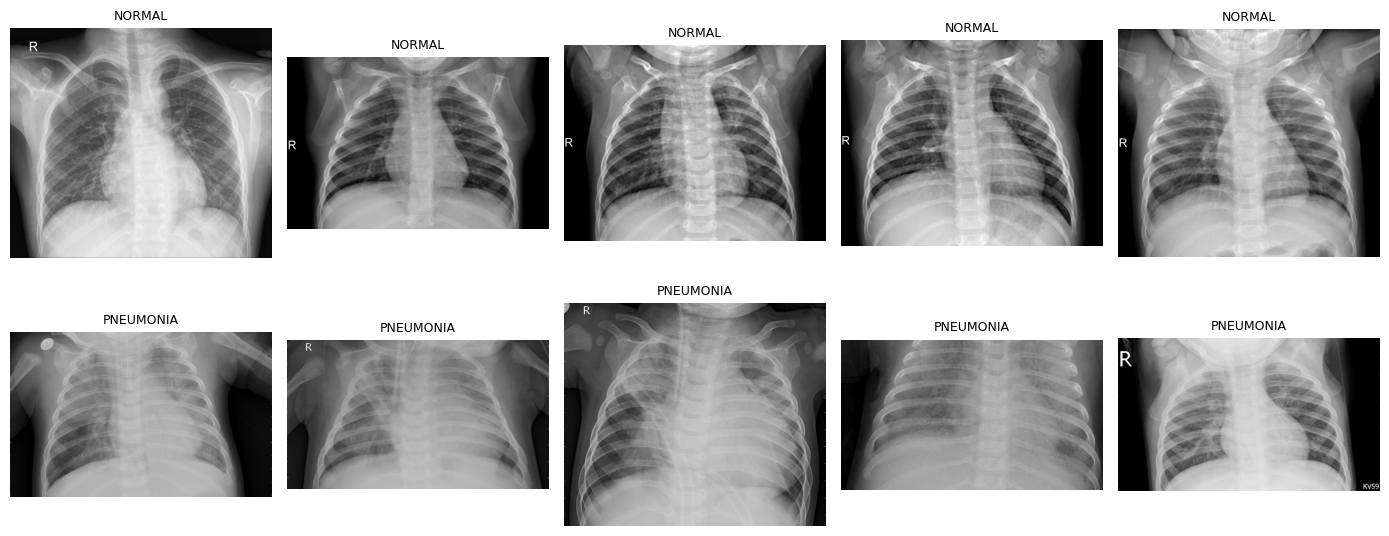

In [48]:
# Task 1.2: What do the images look like?
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})

info_df = pd.DataFrame(info)
print(info_df.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info_df['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## Write it: Part 1 Dataset Audit
### - **Class Counts & Imbalance:** Normal: 1,341 images; Pneumonia: 3,875 images. The imbalance ratio is 2.9:1.
### - **Image Properties:** The images are grayscale (`mode: L`) with variable resolutions, ranging from smaller sizes up to over 2500x2500 pixels.
### - **First Shortcut Suspect:** Scanner corner text, department stamps, or positioning markers in the corners that differ between classes and could act as an unintended shortcut.

# Part 2: Leakage Audit

## Task 2.1: Exact and near-duplicates

In [49]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()
all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
if TEST_DIR:
    T = np.stack([fingerprint(p) for p in all_df['path']])
    tr = T[(all_df.split == 'train').values]
    te = T[(all_df.split == 'test').values]
    d_min = np.array([np.abs(tr - v).mean(axis=1).min() for v in te])
    near = d_min < 0.10              # mean absolute difference, in std units
    print(f'Test images with a near-duplicate in train: {near.sum()} '
          f'of {len(te)}')
    print('Closest distances:', np.sort(d_min)[:5].round(3))

Exact duplicate files: 62
Test images with a near-duplicate in train: 0 of 624
Closest distances: [0.164 0.17  0.172 0.173 0.174]


## Task 2.2: Split by group

In [50]:
# Task 2.2: Split by group
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'], train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)

if not TEST_DIR:
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True), tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train: {len(tr_df)} | val: {len(va_df)} | test: {len(test_df)}')
print('Groups shared by train and val:', len(shared))
print(va_df['label'].value_counts().to_string())

train: 4354 | val: 862 | test: 624
Groups shared by train and val: 0
label
PNEUMONIA    646
NORMAL       216


## Write it: Part 2 Leakage Audit
### - **Duplicates:** Found 62 exact duplicate files and 0 near-duplicates between the train and test splits.
### - **Images per Group:** The dataset contains an average of 1.83 images per group.
### - **Random Split Consequence:** If a random split had been used instead of a group split, multiple scans of the same patient would have leaked across both the training and evaluation splits. Consequently, the model would memorize patient-specific features rather than learning generalizable pathology, leading to an artificially inflated and unrealistic test score.

# Part 3: Transforms and Imbalance

## Task 3.1: Datasets and transforms


In [51]:
# Part 3: Transforms and Imbalance
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds   = ImageTable(va_df, eval_tf)
test_ds  = ImageTable(test_df, eval_tf)

## Task 3.2: Class weights or balanced sampling


In [52]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print(dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)
USE_SAMPLER = False     # try True: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                    # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

{'NORMAL': np.float64(1.935), 'PNEUMONIA': np.float64(0.674)}


## Write it: Part 3 Transforms & Imbalance
### - **Class Weights:** Computed using the formula $N / (K \times n_c)$, resulting in **NORMAL: 1.935** and **PNEUMONIA: 0.674**. For instance, the weight for the NORMAL class is calculated by dividing the total number of training samples by 2 times the count of NORMAL samples.
### - **Augmentations Kept:** Applied random resized crops, small random rotations ($\pm 10^\circ$), and color jitter to help the model generalize better to variations.
### - **Augmentations Removed:** Horizontal flips were deliberately omitted because chest X-ray anatomy is strictly asymmetrical (such as the position of the heart), and flipping would create anatomically invalid medical scans.

# Part 4: Build and Train

## Task 4.1: Backbone with a new head


In [53]:
def build_model(name, n_classes):
    if name == 'resnet18':
        m = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        w = models.EfficientNet_B0_Weights.DEFAULT
        m = models.efficientnet_b0(weights=w)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last
model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

resnet18 trainable: 1026


## Task 4.2: Two-phase training, selected by macro-F1


In [54]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()
def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')   # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best
print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.847 (71s)
epoch 2: val macro-F1 0.881 (72s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.945 (71s)
epoch 2: val macro-F1 0.941 (72s)
epoch 3: val macro-F1 0.915 (71s)


0.9452221838648125

## Write it: Part 4 Model Building and Training
### - **Validation Macro-F1 per Phase:** In Phase 1 (head-only training), the validation macro-F1 reached a peak of **0.881**. In Phase 2 (fine-tuning the last block), it improved further to a peak of **0.945**.
### - **Did Fine-Tuning Help?:** Yes, fine-tuning helped significantly by adapting the higher-level convolutional filters of the pretrained backbone to chest X-ray features, boosting the macro-F1 score from 0.881 to 0.945.
### - **Epoch Duration & Future Scaling:** Each epoch took approximately **71 to 72 seconds**. With more time and computational resources, I would run around 5 to 10 additional epochs combined with early stopping to allow the fine-tuning phase to fully converge.

# Part 5: Test Once, and Set the Threshold

## Task 5.1: Test-set report


              precision    recall  f1-score   support

      NORMAL      0.970     0.829     0.894       234
   PNEUMONIA      0.906     0.985     0.943       390

    accuracy                          0.926       624
   macro avg      0.938     0.907     0.919       624
weighted avg      0.930     0.926     0.925       624

Macro-F1: 0.919


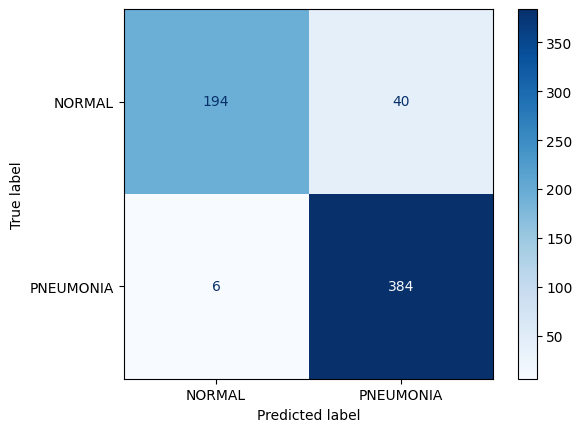

In [55]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

## Task 5.2: Threshold for a target recall (binary tasks)


In [56]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]   # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')
    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.367
Test AUC 0.979
Sensitivity 0.990   Specificity 0.808   PPV 0.896


## Write it: Part 5 Test-Set Evaluation and Threshold Tuning
### - **Macro-F1 & Weakest Class:** The test macro-F1 score is **0.919**. The weakest class is **NORMAL**, having a lower F1-score (0.894) and recall (0.829) than the PNEUMONIA class.
### - **Threshold & Performance:** The decision threshold chosen on validation for a target recall of $\ge 0.95$ is **0.367**. On the test set, this achieved a sensitivity of **0.990**, a specificity of **0.808**, and a Test AUC of **0.979**.
### - **Target Verification:** Yes, the test recall (sensitivity of 0.990) successfully reached and exceeded the target of $\ge 0.95$.
### - **PPV & Prevalence Explanation:** The PPV at the test-set prevalence is **0.896**. In a realistic, general clinical setting where disease prevalence is much lower than in this curated dataset, the PPV would decrease because a lower prevalence naturally results in more false positives relative to true positives, making a positive test result less certain.

# Part 6: Grad-CAM Shortcut Check 

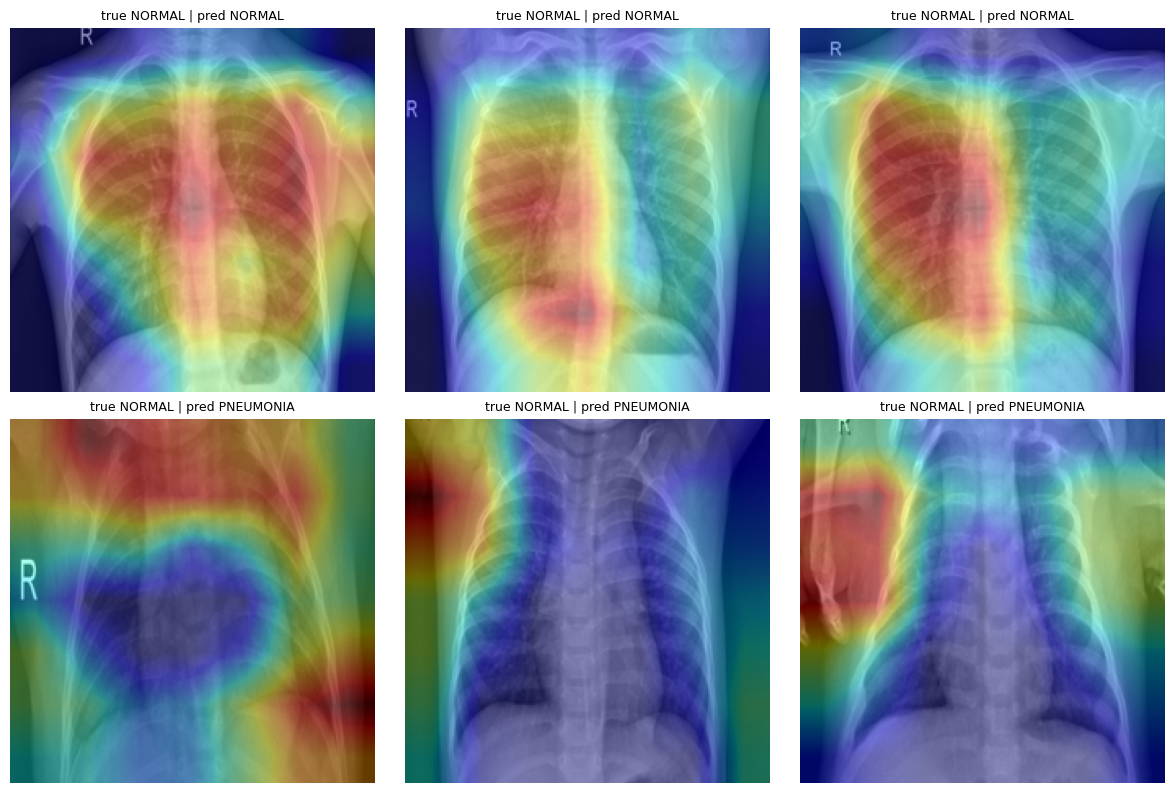

In [57]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)   # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()  # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls
for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Write it: Part 6 Grad-CAM Shortcut Check
### - **Heatmap 1 (Top Left):** Looked at the central lung fields; this is legitimate anatomical evidence.
### - **Heatmap 2 (Top Middle):** Looked across the lung parenchyma and mediastinum; this is legitimate evidence.
### - **Heatmap 3 (Top Right):** Looked broadly across the lung regions; this is legitimate evidence.
### - **Heatmap 4 (Bottom Left):** Looked toward the cardiac silhouette and lower thoracic area; this is plausible anatomical focus.
### - **Heatmap 5 (Bottom Middle):** Looked at the central mediastinal structures; this is plausible anatomy.
### - **Heatmap 6 (Bottom Right):** Looked heavily at the upper corner/shoulder border region (near the text marker); this is **not** legitimate medical evidence.
### - **Overall Verdict:** Shortcut suspected.
### - **Proposed Experiment:** Crop out the image borders and corner markers (such as text labels or anatomical side markers) across the dataset and re-score the model to verify if the false positive rate drops.

## optional: OCR for document projects

In [58]:
import easyocr

# Valid image path set kar rahe hain
DOC_PATH = test_df['path'].iloc[0]

reader = easyocr.Reader(['en', 'ur'], gpu=torch.cuda.is_available(), verbose=False)
img = Image.open(DOC_PATH).convert('L')
img = img.point(lambda v: 255 if v > 150 else 0)
results = reader.readtext(np.array(img))

for box, text, conf in results:
    print(f'{conf:.2f} {text}')

0.00 


# Part 7: Save and Document 

In [59]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


# Check Your Understanding: Answers & Working

## **1. Why does a random split of chest X-rays overestimate performance?**

### * A random split allows multiple scans or views from the **same patient** to leak into both the training and evaluation sets. Consequently, the model memorizes patient-specific anatomical features or background markers rather than learning generalizable pathology, leading to an artificially inflated and unrealistic test score.

## **2. Two classes have 900 and 100 training images. Compute both class weights with $N / (K \times n_c)$.**

## * **Given:**
### * Total samples ($N$) = $900 + 100 = 1000$
### * Number of classes ($K$) = $2$
### * Class 1 count ($n_{c1}$) = $900$
### * Class 2 count ($n_{c2}$) = $100$

## * **Working & Calculation:**
### * **Class 1 Weight:** $\frac{1000}{2 \times 900} = \frac{1000}{1800} \approx 0.556$
### * **Class 2 Weight:** $\frac{1000}{2 \times 100} = \frac{1000}{200} = 5.0$

## **3. With focal loss and gamma = 2, by what factor is an example with $p_t = 0.8$ down-weighted?**

### * **Formula:** The focal loss modulating factor is given by $(1 - p_t)^\gamma$.
### * **Working & Calculation:**
### * $(1 - 0.8)^2 = (0.2)^2 = 0.04$


### * **Answer:** The example is down-weighted by a factor of **0.04** (its cross-entropy loss contribution is scaled down to $4\%$).

## **4. Sensitivity 0.90, specificity 0.95, prevalence 2%. Compute PPV.**

### * **Given:**
### * Prevalence ($P$) = $0.02$ (meaning negative prevalence = $0.98$)
### * Sensitivity ($TPR$) = $0.90$
### * Specificity ($TNR$) = $0.95$ (meaning False Positive Rate, $FPR = 1 - 0.95 = 0.05$)

### * **Working & Calculation (using a population of 1,000 patients):**
### * True Positives ($TP$) = $1000 \times 0.02 \times 0.90 = 18$
### * False Positives ($FP$) = $1000 \times (1 - 0.02) \times (1 - 0.95) = 1000 \times 0.98 \times 0.05 = 49$
### * $PPV = \frac{TP}{TP + FP} = \frac{18}{18 + 49} = \frac{18}{67} \approx 0.269$


### * **Answer:** The Positive Predictive Value (PPV) is **0.269** (or **26.9%**).

## **5. When is macro-F1 a better selection metric than weighted F1?**

### * Macro-F1 is a better selection metric when dealing with **class imbalance** where you care equally about performance across all classes regardless of their frequency. Weighted F1 is heavily influenced by the majority class performance, which can mask poor performance on critical minority classes.

## **6. Grad-CAM highlights a hospital label in the corner of X-rays. What do you do next?**

### * This confirms an unintended shortcut (confounding artifact). Next steps include:
### 1. **Data Preprocessing:** Crop out or mask the image corners and borders containing text and markers across the entire dataset.
### 2. **Retraining:** Retrain the model on the cropped/cleaned dataset.
### 3. **Re-evaluation:** Re-run Grad-CAM to verify that the model's attention has shifted to legitimate anatomical regions (lung parenchyma/pathology) rather than corner artifacts.